# 03_ModelTraining Notebook

In this notebook the prepared data is loaded and used for model training.

This notebook is used to train regression models with engineered features as input and without images as direct input.

## 1. Import libaries and define parameters

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor

In [2]:
goldDir = r'C:\Users\domin\OneDrive\Dokumente\Privat\AlgaeBiotech\IGB-Sensorfusion\Data\03_gold'
dataFile = r'\combinedData.xlsx'

features = ['probeQuantity','iso','redEx','greenEx','blueEx']
label = 'concentration'

## 2. Load data and prepare for training

In [3]:
df = pd.read_excel(goldDir + dataFile)
df.head()

,concentration,probeQuantity,iso,imgNumber,imgFileName,red,green,blue,redEx,greenEx,blueEx
0,0.5,20,800,1542,IMG_1542.JPG,202.267379,177.403036,130.979161,202.267379,177.403036,130.979161
1,0.5,20,800,1543,IMG_1543.JPG,201.236557,176.150268,129.861151,201.236557,176.150268,129.861151
2,0.5,20,800,1544,IMG_1544.JPG,201.829144,177.143131,130.098434,201.829144,177.143131,130.098434
3,0.5,20,800,1545,IMG_1545.JPG,201.773849,177.068339,130.089377,201.773849,177.068339,130.089377
4,0.5,40,800,1546,IMG_1546.JPG,192.273503,171.378659,114.703927,192.273503,171.378659,114.703927


### Scale data

In [4]:
# only use features for scaling
scaler = MinMaxScaler()
scaledData = scaler.fit_transform(df[features])
scaledData

array([[0.        , 0.        , 0.75999123, 0.64706888, 0.50179603],
       [0.        , 0.        , 0.7551998 , 0.64129658, 0.49692172],
       [0.        , 0.        , 0.75795424, 0.64587134, 0.49795623],
       [0.        , 0.        , 0.75769722, 0.64552672, 0.49791675],
       [1.        , 0.        , 0.71353806, 0.61931073, 0.43083921],
       [1.        , 0.        , 0.71384261, 0.61986979, 0.43076491],
       [0.        , 0.        , 0.72044674, 0.62044192, 0.44520092],
       [0.        , 0.        , 0.72008228, 0.62225077, 0.44741789],
       [1.        , 0.        , 0.63487317, 0.56587345, 0.40092712],
       [1.        , 0.        , 0.63362251, 0.5641288 , 0.39983924],
       [0.        , 0.        , 0.67739663, 0.59415992, 0.41872959],
       [0.        , 0.        , 0.67764198, 0.59425263, 0.41767951],
       [0.        , 0.        , 0.67708187, 0.59430014, 0.41687189],
       [1.        , 0.        , 0.57484222, 0.51192601, 0.39992655],
       [1.        , 0.        , 0.

### Create train test split
Training Images are: 1542 - 1652 / 0 - 110

Testing Images are: 1653 - 1700 / 111 - 158

Images with label zero: 1639 - 1652 / 97 - 110

In [5]:
# calculate train test split
111 / 159

0.6981132075471698

In [6]:
X_train = scaledData[0:111]
y_train = df[label][0:111].values
X_test = scaledData[111:]
y_test = df[label][111:].values

## 3. Define and train model

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [19]:
model2 = regr = MLPRegressor(hidden_layer_sizes=(5,5), random_state=1, max_iter=2000, tol=0.1)
model2.fit(X_train, y_train)

MLPRegressor(hidden_layer_sizes=(5, 5), max_iter=2000, random_state=1, tol=0.1)

## 4. Evaluate model performance

### Training performance

In [20]:
print('Model score:', model.score(X_train, y_train))
print('Model2 score:', model2.score(X_train, y_train))

Model score: 0.669590361270495
Model2 score: -2.4252682290102614


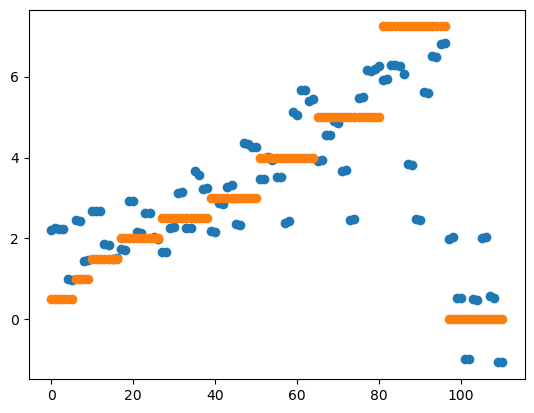

In [21]:
plt.scatter(range(len(y_train)), model.predict(X_train))
plt.scatter(range(len(y_train)), y_train)

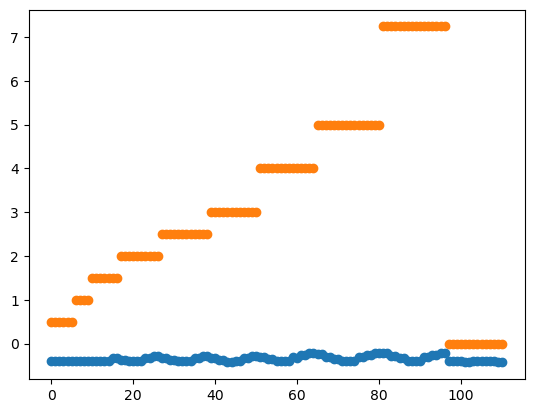

In [22]:
plt.scatter(range(len(y_train)), model2.predict(X_train))
plt.scatter(range(len(y_train)), y_train)

### Testing performance

In [16]:
print('Model score:', model.score(X_test, y_test))
print('Model2 score:', model2.score(X_test, y_test))

Model score: 0.716264664492301
Model2 score: -0.6403940308846587


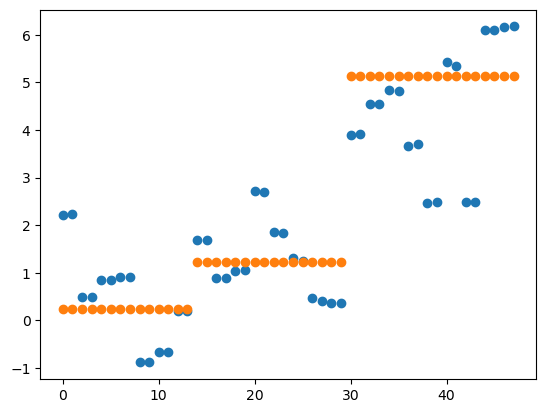

In [17]:
plt.scatter(range(len(y_test)), model.predict(X_test))
plt.scatter(range(len(y_test)), y_test)